# Pulse encoder output

Runs the **trained** per-DOM pulse encoder (`trainer_domenc.DOMPulseEncoder`) of a finished run on a few thousand events and plots
its 32-d output per DOM — the learned summary of each DOM's charge-vs-time pulse series that feeds the GAT.

Data: the 1k-per-flavour samples with the same preprocessing as the run (incl. its DOM charge cut). Most of these events were also
in the 40k training sample, so the flavour comparison at the end is descriptive, not an unbiased test.

In [8]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "8")   # dev nodes kill processes over their CPU-time limit

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.decomposition import PCA
from torch_geometric.loader import DataLoader

ANA = "/mnt/scratch/baburish/doublepulse/gnn/Analysis"
sys.path.insert(0, ANA)
import trainer as tr
import trainer_domenc as td

RUN_DIR = f"/mnt/scratch/baburish/doublepulse/gnn/Analysis/trained_model5TeV/full_nodist_aux1_bs64"   # any finished trainer_domenc run
RUN_DIR = "/mnt/scratch/baburish/doublepulse/gnn/Analysis/trained_model5TeV/test40k_gat_cut10_arch_feats_t33_gelu"
DBS = {"nutau": f"{ANA}/data/combined_nutau_5TeV_1k.db", "nue": f"{ANA}/data/combined_nue_5TeV_1k.db"}

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COL = {"nutau": "#2a78d6", "nue": "#eb6834"}
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#a8302f", "#e34948", "#f2a3a2", "#f0efec", "#9ec5f4", "#2a78d6", "#184f95"])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "axes.labelcolor": INK,
                     "axes.edgecolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "legend.frameon": False})

## 1. Load the trained model (settings from `run_config.json`) and build the events

In [9]:
cfg = json.load(open(f"{RUN_DIR}/run_config.json"))
assert cfg["trainer"] == "trainer_domenc", "needs a trainer_domenc run (it has the pulse encoder)"
state = torch.load(f"{RUN_DIR}/hybrid_weights.pt", map_location="cpu")
model = td.HybridGNNClassifier(
    n_node_features=td.node_features_in_weights(state, bright_feats=cfg.get("bright_feats", False)),   # 13 for older runs
    use_pca=not cfg.get("no_pca", False), n_aux=td.N_AUX if cfg.get("aux_weight", 0) > 0 else 0,
    use_image=cfg.get("use_image", False) or cfg.get("image_only", False), use_gnn=not cfg.get("image_only", False),
    readout=cfg.get("gat_readout", "sum"), residual=cfg.get("gat_residual", False),
    bright_feats=cfg.get("bright_feats", False), extra_edges=cfg.get("extra_edges", False),
    full_graph=cfg.get("full_graph", False),
    time_unit_ns=cfg.get("time_unit_ns") or None, pulse_act=cfg.get("pulse_act", "relu"))
model.load_state_dict(state)
model.eval()
MIN_DOM_Q = cfg.get("min_dom_charge", 0.0)
print(f"run {os.path.basename(RUN_DIR)} | DOM cut {MIN_DOM_Q} PE | pulse features {td.PULSE_FEATURE_NAMES}")

geo = pd.read_csv(f"{ANA}/geometry_clean.csv")
kd_tree, sid_geo = tr.build_geo_dict_kdtree(geo)
td.set_geometry(kd_tree, sid_geo)


class SerialKD:
    """Same KD-tree query as training, single-threaded (the trainer asks for all cores per event)."""
    def __init__(self, tree):
        self.tree = tree

    def query(self, pts, workers=1, **kw):
        return self.tree.query(pts, workers=1, **kw)


ds = tr.HybridNeutrinoDataset(nue_dbs=DBS["nue"], tau_dbs=DBS["nutau"], kd_tree=SerialKD(kd_tree), string_ids_geo=sid_geo,
                              charge_threshold=cfg.get("charge_threshold", 0.1), min_dom_charge=MIN_DOM_Q,
                              graph_fn=td.event_to_dom_pulse_graph)

run test40k_gat_cut10_arch_feats_t33_gelu | DOM cut 10.0 PE | pulse features ['dt_first', 'dt_prev', 'q_log', 'q_frac_dom', 'cumq_frac']
Loading tau events from 1 file(s)...


  tau files: 100%|██████████| 1/1 [00:05<00:00,  5.21s/file]


  -> Loaded 833 tau events
Loading nue events from 1 file(s)...


  nue files: 100%|██████████| 1/1 [00:05<00:00,  5.24s/file]


  -> Loaded 836 nue events
Class imbalance detected (tau=833, nue=836) -- balancing both to 833

Dataset summary:
  Tau:  833
  Nue:  833
Ratio: 1:1 (balanced)
Collating dataset...


## 2. Run the pulse encoder

In [10]:
rows, EMB, EVENTS = [], [], []
with torch.no_grad():
    for b in DataLoader(ds, batch_size=64):
        emb = model.encode_pulses(b)          # [DOMs, 32]; same input rescaling as in training
        bright = td.brightest_index(b.x, b.batch)
        is_b = torch.zeros(b.num_nodes, dtype=torch.bool); is_b[bright] = True
        ev0 = len(EVENTS)
        for g in range(b.num_graphs):
            m = (b.batch == g)
            pm = m[b.pulse_dom]
            EVENTS.append(dict(flavor="nutau" if b.y[g] == 1 else "nue", emb=emb[m].numpy(), x=b.x[m].numpy(),
                               pulse_x=b.pulse_x[pm].numpy(), pulse_dom=(b.pulse_dom[pm] - torch.nonzero(m)[0, 0]).numpy()))
        EMB.append(emb.numpy())
        rows.append(pd.DataFrame({"event": ev0 + b.batch.numpy(), "flavor": np.where(b.y[b.batch] == 1, "nutau", "nue"),
                                  "q_log": b.x[:, 3].numpy(), "t_first_ns": 500 * b.x[:, 5].numpy(),
                                  "t_spread_ns": 500 * b.x[:, 7].numpy(), "n_pulses": 10 * b.x[:, 8].numpy(),
                                  "brightest": is_b.numpy()}))
EMB = np.concatenate(EMB)
DOMS = pd.concat(rows, ignore_index=True)
print(f"{len(EVENTS)} events, {len(DOMS)} DOMs, embedding dim {EMB.shape[1]} | "
      f"dimensions never active (always 0 after ReLU): {(EMB.max(0) == 0).sum()}")

1666 events, 35485 DOMs, embedding dim 32 | dimensions never active (always 0 after ReLU): 0


## 3. One event: pulse series and encoder output
Left: each DOM's charge vs time (time since the DOM's first pulse), brightest DOM on top. Right: that DOM's 32-d encoder output.

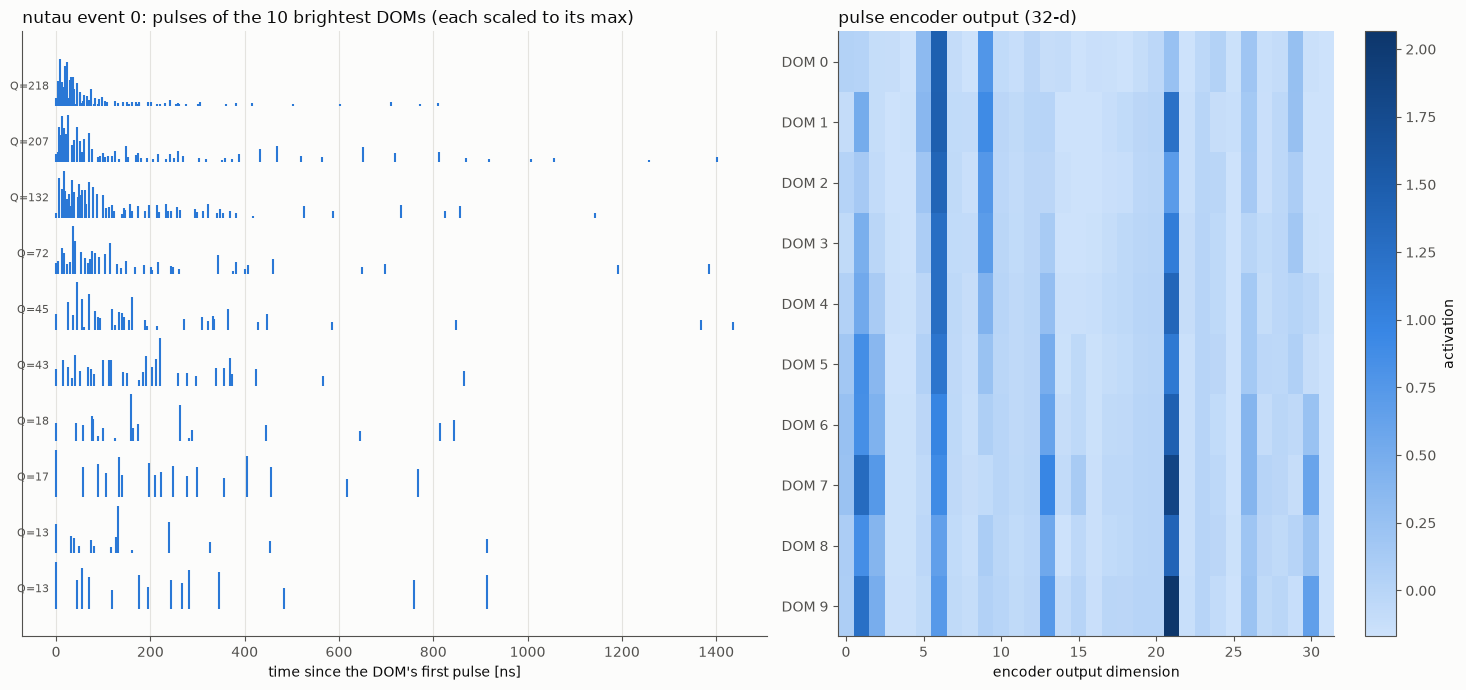

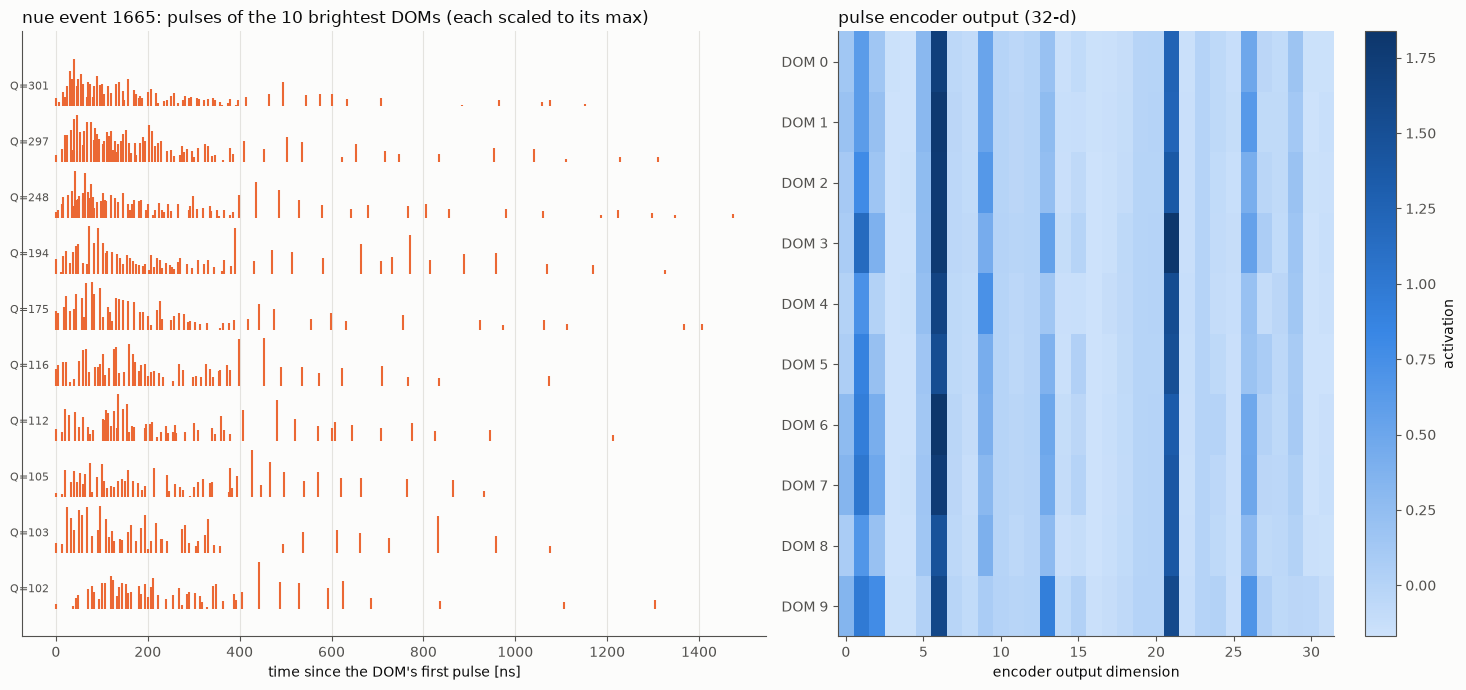

In [11]:
def show_event(i, max_doms=10):
    ev = EVENTS[i]
    order = np.argsort(-ev["x"][:, 3])[:max_doms]                       # DOMs by charge
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 0.55 * len(order) + 1.5), gridspec_kw={"width_ratios": [1.2, 1]})
    for r, d in enumerate(order):
        p = ev["pulse_x"][ev["pulse_dom"] == d]
        t_ns, q = 500 * p[:, 0], np.expm1(p[:, 2])
        a1.vlines(t_ns, -r, -r + 0.85 * q / q.max(), color=COL[ev["flavor"]], linewidth=1.5)
        a1.text(-15, -r + 0.3, f"Q={np.expm1(ev['x'][d, 3]):.0f}", ha="right", fontsize=8, color=INK_2)
    a1.set_yticks([]); a1.set_xlabel("time since the DOM's first pulse [ns]")
    a1.set_title(f"{ev['flavor']} event {i}: pulses of the {len(order)} brightest DOMs (each scaled to its max)", loc="left")
    im = a2.imshow(ev["emb"][order], aspect="auto", cmap=SEQ, interpolation="nearest")
    a2.set_yticks(range(len(order)), [f"DOM {k}" for k in range(len(order))]); a2.grid(False)
    a2.set_xlabel("encoder output dimension"); a2.set_title("pulse encoder output (32-d)", loc="left")
    fig.colorbar(im, ax=a2, label="activation")
    fig.tight_layout(); plt.show()


show_event(0)
show_event(len(EVENTS) - 1)

## 4. All DOMs: 2D projection (PCA) of the encoder output

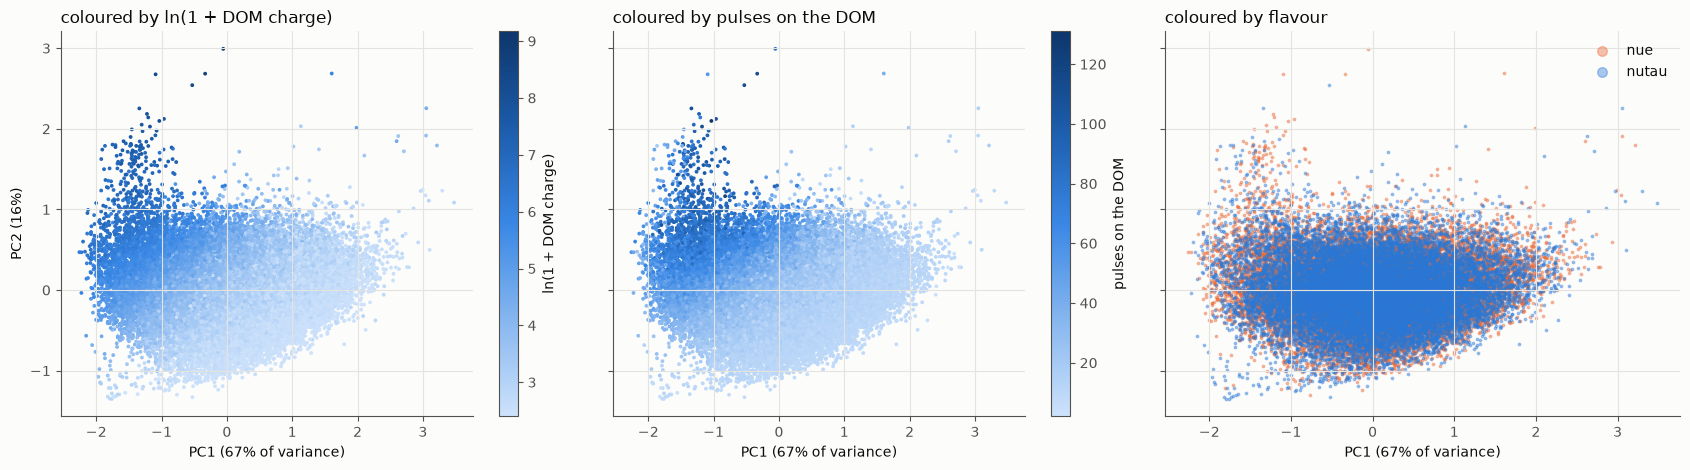

In [12]:
pca = PCA(2).fit(EMB)
P = pca.transform(EMB)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharex=True, sharey=True)
for ax, (col, label) in zip(axes[:2], [("q_log", "ln(1 + DOM charge)"), ("n_pulses", "pulses on the DOM")]):
    sc = ax.scatter(P[:, 0], P[:, 1], c=DOMS[col], s=3, cmap=SEQ, rasterized=True)
    fig.colorbar(sc, ax=ax, label=label); ax.set_title(f"coloured by {label}", loc="left")
for fl in ["nue", "nutau"]:
    m = (DOMS["flavor"] == fl).to_numpy()
    axes[2].scatter(P[m, 0], P[m, 1], s=3, alpha=0.4, color=COL[fl], label=fl, rasterized=True)
axes[2].legend(loc="upper right", markerscale=4); axes[2].set_title("coloured by flavour", loc="left")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
fig.tight_layout(); plt.show()

## 5. What the output dimensions track
Correlation of each output dimension with simple DOM summaries. Dimensions that follow `q_log` / `n_pulses` only re-encode
brightness; dimensions with weak correlation to all of them carry pulse-shape information beyond the summaries.

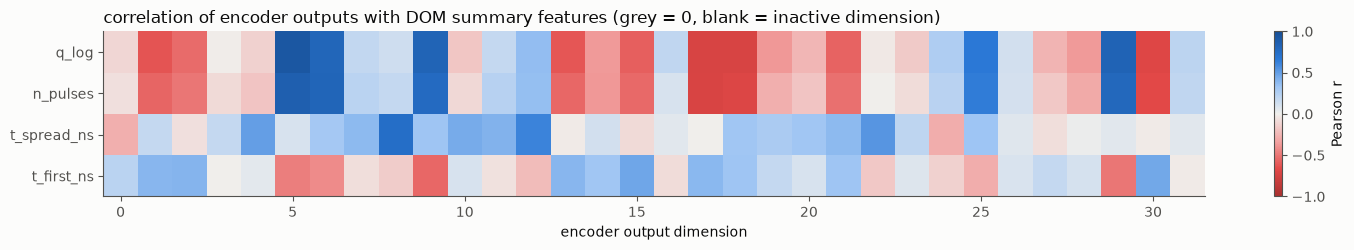

dimensions with max |r| < 0.3 to all summaries: 8 of 32


In [13]:
summ = ["q_log", "n_pulses", "t_spread_ns", "t_first_ns"]
corr = np.array([[np.corrcoef(EMB[:, k], DOMS[s])[0, 1] if EMB[:, k].std() > 0 else np.nan for k in range(EMB.shape[1])]
                 for s in summ])
fig, ax = plt.subplots(figsize=(15, 2.6))
im = ax.imshow(corr, aspect="auto", cmap=DIV, norm=TwoSlopeNorm(0, -1, 1), interpolation="nearest")
ax.set_yticks(range(len(summ)), summ); ax.set_xlabel("encoder output dimension"); ax.grid(False)
ax.set_title("correlation of encoder outputs with DOM summary features (grey = 0, blank = inactive dimension)", loc="left")
fig.colorbar(im, ax=ax, label="Pearson r"); fig.tight_layout(); plt.show()
best = np.nanmax(np.abs(corr), axis=0)
print(f"dimensions with max |r| < 0.3 to all summaries: {int(np.sum(best < 0.3))} of {EMB.shape[1]}")

## 6. Brightest DOM: encoder output, nutau vs nue

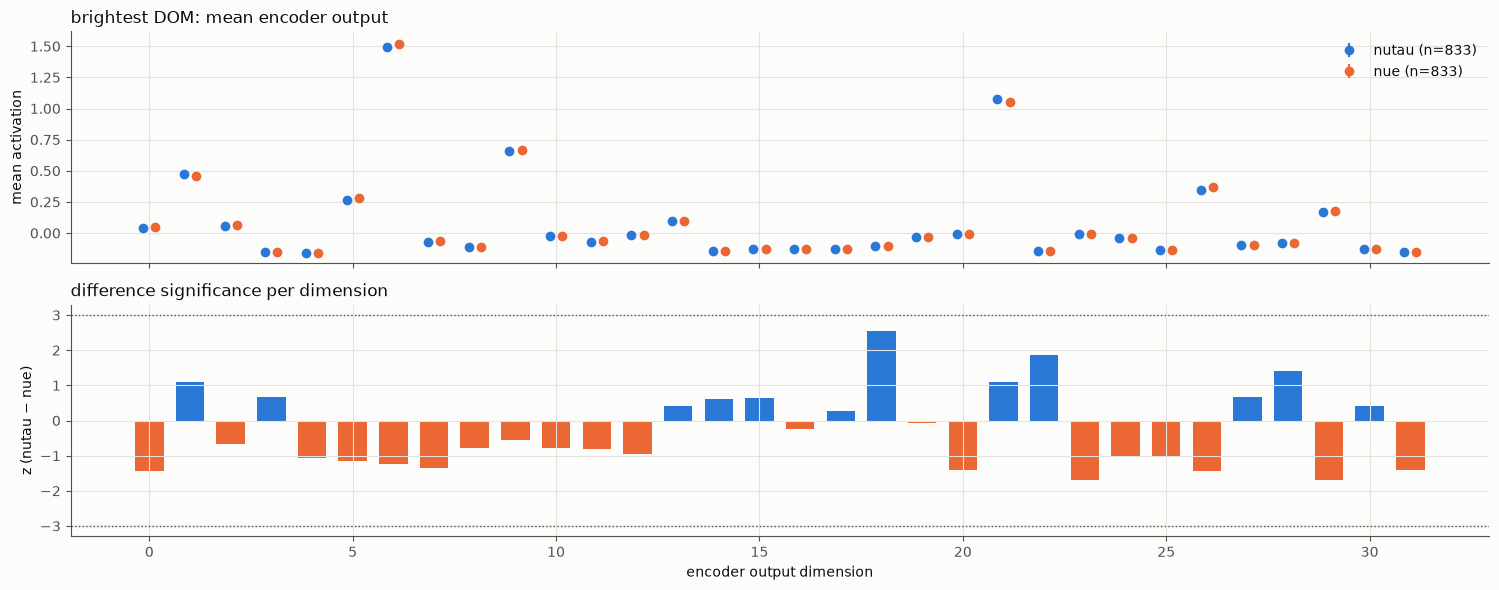

In [14]:
b = DOMS["brightest"].to_numpy()
e1, e0 = EMB[b & (DOMS["flavor"] == "nutau").to_numpy()], EMB[b & (DOMS["flavor"] == "nue").to_numpy()]
z = (e1.mean(0) - e0.mean(0)) / np.sqrt(e1.var(0) / len(e1) + e0.var(0) / len(e0) + 1e-12)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
k = np.arange(EMB.shape[1])
a1.errorbar(k - 0.15, e1.mean(0), yerr=e1.std(0) / np.sqrt(len(e1)), fmt="o", color=COL["nutau"], label=f"nutau (n={len(e1)})")
a1.errorbar(k + 0.15, e0.mean(0), yerr=e0.std(0) / np.sqrt(len(e0)), fmt="o", color=COL["nue"], label=f"nue (n={len(e0)})")
a1.set_ylabel("mean activation"); a1.legend(loc="upper right"); a1.set_title("brightest DOM: mean encoder output", loc="left")
a2.bar(k, z, color=np.where(z > 0, COL["nutau"], COL["nue"]), width=0.7)
for h in (-3, 3):
    a2.axhline(h, color=INK_2, linestyle=":", linewidth=1)
a2.set_ylabel("z (nutau − nue)"); a2.set_xlabel("encoder output dimension")
a2.set_title("difference significance per dimension", loc="left")
fig.tight_layout(); plt.show()